In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple
from pathlib import Path
import os
from glob import glob

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys
import h5py
from scipy import signal
# Add src to path for custom utilities
sys.path.insert(0, f'/home/obandohe/JIPSENSE/JIPSENSE')
from src.utils.seismic_io import load_traces_from_hdf5, print_hdf5_info
from src.utils.fk_spectrum_class import FKSpectrum
from src.utils.Preprocessing_SW import agc_gain, Array_to_ObsPy
import src.utils.wft as wft
from obspy.signal.tf_misfit import cwt
print("✓ All libraries imported successfully")

✓ All libraries imported successfully


In [25]:
def getSpectrum(data_mod,fs,dx,fmin,fmax,vel_min,vel_max):
    ''' Function to compute the wavefield transform of a given data set
    Parameters:
    data_mod: data to be transformed
    fs: sampling frequency in Hz
    dx: receiver spacing in meters
    fmin: minimum frequency in Hz
    fmax: maximum frequency in Hz
    vel_min: minimum velocity in m/s
    vel_max: maximum velocity in m/s

    returns:
    power: power spectrum 
    power_norm: normalized power spectrum
    frequencies: frequencies
    velocities: velocities

    '''
    # receiver coordinates
    offsets = np.arange(data_mod.shape[1])*dx
    # velocity range
    velocities = np.linspace(vel_min,vel_max,250)
    # parameters for the wavefield transform
    settings = {'fmin':fmin,'fmax':fmax,'fdbf_weighting':'sqrt','fdbf_steering':'cylindrical'}
    # normalize data
    data_norm = data_mod/np.max(np.abs(data_mod),axis=0)
    # perform wavefield transform
    tmatrix = np.transpose(data_norm)
    frequencies, power = wft.phase_shift(tmatrix, offsets, fs, velocities, settings)
    # normalize power spectrum
    power_norm = np.abs(power)/np.max(np.abs(power),axis=0)

    return np.abs(power), power_norm, frequencies, velocities



def read_trace_file(semp_file: Path) -> Tuple[np.ndarray, np.ndarray, float]:
    """
    Read a SPECFEM2D seismic trace file (.semp format).
    
    Format: Two columns separated by whitespace
    - Column 1: Time (seconds)
    - Column 2: Pressure/Amplitude
    
    Args:
        semp_file: Path to .semp file
        
    Returns:
        Tuple of (time array, pressure array, dt)
    """
    try:
        data = np.loadtxt(semp_file)
        
        if data.ndim == 1:
            # Single sample (unlikely, but handle it)
            time = np.array([data[0]])
            pressure = np.array([data[1]])
        else:
            time = data[:, 0]
            pressure = data[:, 1]
        
        # Compute dt from time differences
        if len(time) > 1:
            dt = float(np.mean(np.diff(time)))
        else:
            dt = 1.0  # Default if only one sample
        
        return time, pressure, dt
    
    except Exception as e:
        print(f"Error reading {semp_file}: {e}")
        return None, None, None



def save_data_mod_to_h5(data_mod, fs, station_coords, params, filename):
    with h5py.File(filename, "w") as f:
        f.create_dataset("data", data=data_mod)
        f.create_dataset("fs", data=fs)
        f.create_dataset("receiver_coordinates", data=station_coords)
        f.create_dataset("params", data=str(params))
    print(f"Data saved to {filename}")


# create psd function using scipy
def compute_psd(data, fs, nfft=1024):
    """
    Compute the Power Spectral Density (PSD) of a given signal using scipy.
    
    Args:
        data: Input signal (1D numpy array)
        fs: Sampling frequency in Hz
        nfft: Number of points for the FFT (default: 1024)
        
    Returns:
        f: Array of sample frequencies
        psd: Power spectral density of the signal
    """

    f, psd = signal.welch(data, fs=fs, nfft=nfft, scaling='density')
    return f, psd

freq_min: 0.0 freq_max: 1000.0
freq_min: 0.0 freq_max: 1000.0
freq_min: 0.0 freq_max: 1000.0
freq_min: 0.0 freq_max: 1000.0


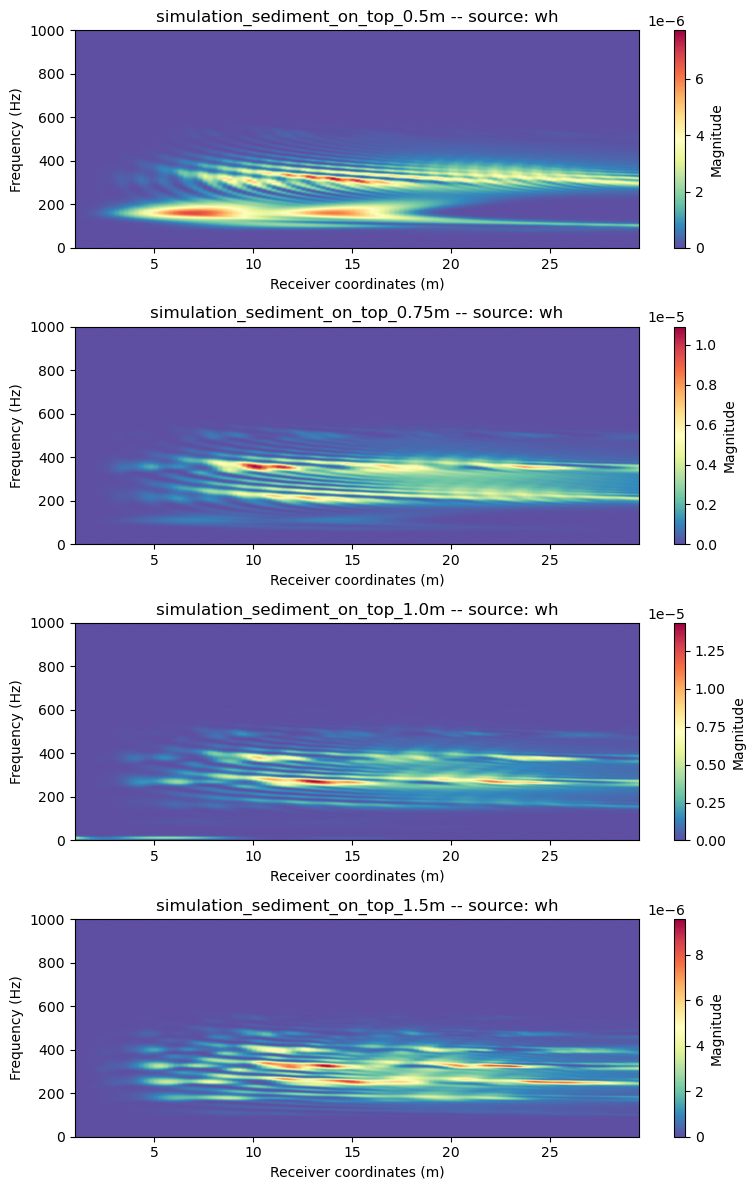

In [26]:
# read STATIONS

full_psd = []
#models = ['simulation_no_sediment_on_top', 'simulation_sediment_on_top', 'simulation_lateral_variation','simulation_inclined_layer']

models = ['simulation_sediment_on_top_0.5m','simulation_sediment_on_top_0.75m', 'simulation_sediment_on_top_1.0m','simulation_sediment_on_top_1.5m']

fig,axs = plt.subplots(len(models),1,figsize=(8,12))


for ii, model_name in enumerate(models):

    signal_type = 'PRE.semp'

    if signal_type=='PRE.semp':
        signal_suffix = 'pressure'
    elif signal_type=='FXX.semv':
        signal_suffix = 'VXX'
    elif signal_type=='FXZ.semv':
        signal_suffix = 'VXZ'
    else:
        raise ValueError(f"Unsupported signal type: {signal_type}")

    source_type = 'wh'  # or 'tr'

    # test saving and loading the h5 file
    filename = f"/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/hdf5_files/{model_name}_{signal_suffix}_{source_type}.h5"
    with h5py.File(filename, "r") as f:
        data_loaded = f["data"][:]
        fs_loaded = f["fs"][()]
        station_coords_loaded = f["receiver_coordinates"][:]
        params_loaded = f["params"][()].decode("utf-8")


    # select a subset of the data if needed
    # Example: select the first 1000 time samples and first 50 receivers
    data_loaded = data_loaded[:420, :]
    #station_coords_loaded = station_coords_loaded[:10, :]

    # Plot data_loaded as a quick check
    #fig_data, ax_data = plt.subplots(figsize=(8, 3))
    #im_data = ax_data.imshow(data_loaded.T, aspect='auto', cmap='Spectral_r')
    #fig_data.colorbar(im_data, ax=ax_data, label='Amplitude')
    #ax_data.set_xlabel('Time samples')
    #ax_data.set_ylabel('Receiver index')
    #ax_data.set_title(f"Data Loaded - {model_name}")


    # Load a trace and extract basic params
    dt = 1/fs_loaded
    psd_all = []
    for i in range(data_loaded.shape[1]):
        data = data_loaded[:,i]

        # Execute the Continuous Wavelet Transform
        # Returns a 2D complex array of wavelet coefficients

        freqs, psd = compute_psd(data, fs_loaded)

        psd_all.append(psd)

    full_psd.append(psd_all)

    print('freq_min:', freqs[0], 'freq_max:', freqs[-1])

    # Convert list to numpy array for easier manipulation
    psd_all = np.array(psd_all)
    

    im = axs[ii].imshow(psd_all.T,aspect='auto',cmap='Spectral_r', interpolation='kaiser',
                        extent=[station_coords_loaded[:,0].min(), station_coords_loaded[:,0].max(), 
                                freqs[0], freqs[-1]], origin='lower')
    fig.colorbar(im, ax=axs[ii], label='Magnitude')
    axs[ii].set_xlabel('Receiver coordinates (m)')
    axs[ii].set_ylabel('Frequency (Hz)')
    axs[ii].set_title(f"{model_name} -- source: {source_type}")

    # set y limits for frequency axis
    axs[ii].set_ylim(freqs[0], freqs[-1])

plt.tight_layout()



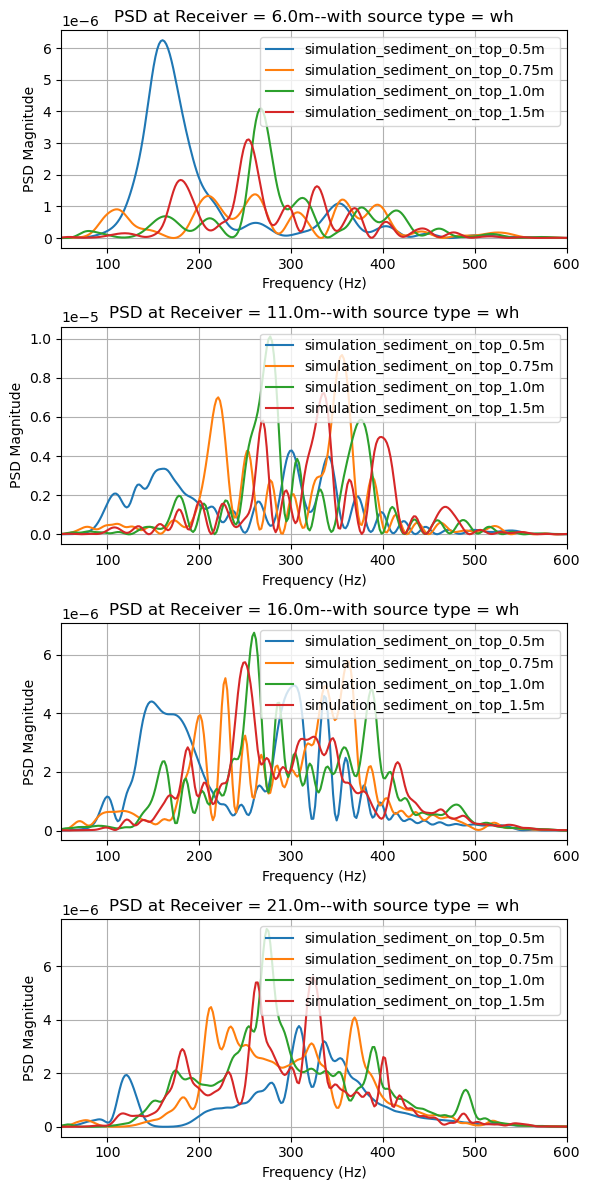

In [27]:
# plot full_psd

full_psd = np.array(full_psd)
#full_psd_mean = np.mean(full_psd, axis=1)

rec_range = [20,40,60,80]

fig, ax = plt.subplots(len(rec_range),1,figsize=(6, 12))

for ii, rec_idx in enumerate(rec_range):
    ax_ = ax[ii] if len(rec_range) > 1 else ax

    full_psd_mean = full_psd[:,rec_idx]
    # plot full_psd_mean

    im = ax_.plot(freqs, full_psd_mean.T)
    ax_.set_xlabel('Frequency (Hz)')
    ax_.set_ylabel('PSD Magnitude')
    ax_.set_title(f'PSD at Receiver = {station_coords_loaded[rec_idx,0]}m--with source type = {source_type}')
    # add legend
    ax_.legend([f'{models[i]}' for i in range(full_psd_mean.shape[0])])
    ax_.grid(True)

    # define x limits
    ax_.set_xlim([50, 600])

    plt.tight_layout()

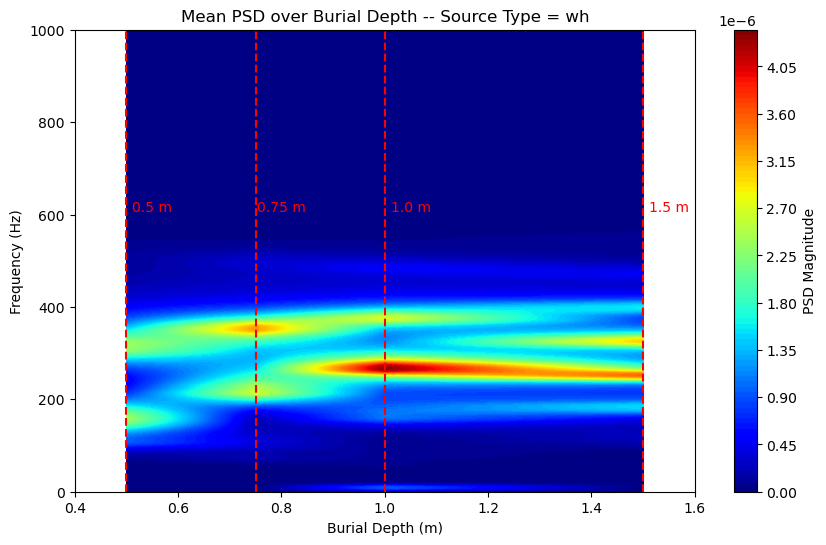

In [28]:
full_psd.shape

psd_mean_over_dist = np.mean(full_psd, axis=1)

burial_depths = np.array([0.5, 0.75, 1.0, 1.5])  # example burial depths corresponding to the models

# create a mesh grid for burial depths and frequencies for plotting
burial_depths_mesh, freqs_mesh = np.meshgrid(burial_depths, freqs)

plt.figure(figsize=(10, 6))
plt.contourf(burial_depths_mesh, freqs_mesh, np.array(psd_mean_over_dist).T, levels=100,cmap='jet')
plt.colorbar(label='PSD Magnitude')
plt.xlabel('Burial Depth (m)')
plt.ylabel('Frequency (Hz)')
plt.title(f'Mean PSD over Burial Depth -- Source Type = {source_type}')

# set the x-axis limits to match the burial depths
plt.xlim(burial_depths[0]-0.1, burial_depths[-1]+0.1)

#plt.ylim(100, 600)


# add vertical lines with text for each burial depth
for depth in burial_depths:
    plt.axvline(x=depth, color='red', linestyle='--')
    plt.text(depth+0.05, 600, f'{depth} m', color='red', ha='center', va='bottom')


plt.show()



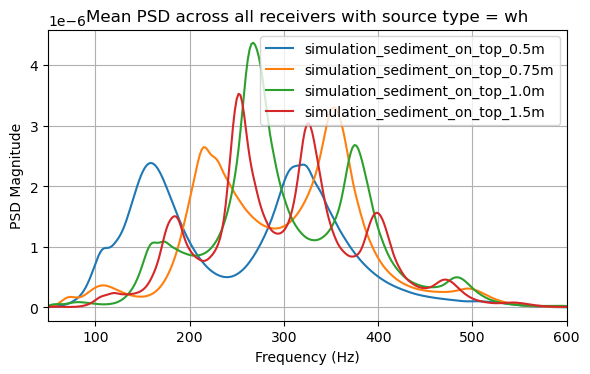

In [29]:
# plot full_psd
full_psd = np.array(full_psd)
full_psd_mean = np.mean(full_psd, axis=1)
fig, ax = plt.subplots(1,1,figsize=(6, 4))
# plot full_psd_mean
im = ax.plot(freqs, full_psd_mean.T)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD Magnitude')
ax.set_title(f'Mean PSD across all receivers with source type = {source_type}')
# add legend
ax.legend([f'{models[i]}' for i in range(full_psd_mean.shape[0])])
ax.grid(True)
ax.set_xlim([50, 600])
plt.tight_layout()

In [30]:
data_loaded.shape

(420, 115)